In [2]:
# Install required packages
!pip install --upgrade sympy --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 74.1 MB/s eta 0:00:00:00:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.6.0+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.5.3.2 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-cupti-cu12==12.4.127; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cuda-cupti-cu12 12.5.82 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-nvrtc-cu12==12.4.127; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cuda-nvrtc-cu12 12.5.82 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-runtime-cu12==12.4.127; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cuda-runtime-cu12 12.5.82 which is

In [3]:
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, random_split
from transformers import ViTForImageClassification
import matplotlib.pyplot as plt
from tqdm import tqdm
from collections import Counter
import os
import random


# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# Define transformations
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


2025-09-12 15:43:53.769693: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1757691833.969564      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1757691834.034138      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


cuda


In [4]:
data_dir = '/kaggle/input/nct-crc-he-100k/NCT-CRC-HE-100K'
balanced_dir = '/kaggle/working/NCT_balanced'
os.makedirs(balanced_dir, exist_ok=True)
categories = ["MUC", "TUM", "DEB", "BACK", "ADI", "MUS", "NORM", "LYM", "STR"]
target_size = 5000

for cls in categories:
    src_path = os.path.join(data_dir, cls)
    dst_path = os.path.join(balanced_dir, cls)
    os.makedirs(dst_path, exist_ok=True)
    files = os.listdir(src_path)
    if len(files) > target_size:
        selected = random.sample(files, target_size)
    else:
        selected = files.copy()
        while len(selected) < target_size:
            selected.append(random.choice(files))
    for i, f in enumerate(selected):
        src_file = os.path.join(src_path, f)
        dst_file = os.path.join(dst_path, f"{i}_{f}")
        if not os.path.exists(dst_file):
            try:
                os.symlink(src_file, dst_file)
            except FileExistsError:
                pass
print("✅ Balanced dataset created with symlinks at:", balanced_dir)

✅ Balanced dataset created with symlinks at: /kaggle/working/NCT_balanced


In [6]:
# Load dataset
dataset = datasets.ImageFolder(root="/kaggle/working/NCT_balanced", transform=transform_train)

# Print dataset details
print("Classes:", dataset.classes)
print("Class-to-Index Mapping:", dataset.class_to_idx)

# Class distribution
labels = [sample[1] for sample in dataset.samples]
print("Class Distribution:", Counter(labels))

Classes: ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
Class-to-Index Mapping: {'ADI': 0, 'BACK': 1, 'DEB': 2, 'LYM': 3, 'MUC': 4, 'MUS': 5, 'NORM': 6, 'STR': 7, 'TUM': 8}
Class Distribution: Counter({0: 5000, 1: 5000, 2: 5000, 3: 5000, 4: 5000, 5: 5000, 6: 5000, 7: 5000, 8: 5000})


In [7]:
# Load dataset
test_dataset = datasets.ImageFolder(root="/kaggle/input/crc-val-he-7k/CRC-VAL-HE-7K", transform=transform_test)

# Print dataset details
print("Classes:", test_dataset.classes)
print("Class-to-Index Mapping:", test_dataset.class_to_idx)

# Class distribution
labels = [sample[1] for sample in test_dataset.samples]
print("Class Distribution:", Counter(labels))

Classes: ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
Class-to-Index Mapping: {'ADI': 0, 'BACK': 1, 'DEB': 2, 'LYM': 3, 'MUC': 4, 'MUS': 5, 'NORM': 6, 'STR': 7, 'TUM': 8}
Class Distribution: Counter({0: 1338, 8: 1233, 4: 1035, 1: 847, 6: 741, 3: 634, 5: 592, 7: 421, 2: 339})


In [8]:
# Dataset split
total_size = len(dataset)
train_size = int(0.7 * total_size)
#val_size = int(0.3 * total_size)
val_size = total_size - train_size

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# Apply test transformations
val_dataset.dataset.transform = transform_test
#test_dataset.dataset.transform = transform_test


# Verify split sizes
print("Train Dataset Size:", len(train_dataset))
print("Validation Dataset Size:", len(val_dataset))
print("Test Dataset Size:", len(test_dataset))

# Data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Define Vision Transformer (ViT) Model
class ViTClassifier(nn.Module):
    def __init__(self, num_classes):
        super(ViTClassifier, self).__init__()
        self.vit = ViTForImageClassification.from_pretrained(
            "google/vit-base-patch16-224-in21k",
            num_labels=num_classes
        )
        self.dropout = nn.Dropout(0.0)

    def forward(self, x):
        logits = self.vit(x).logits
        return self.dropout(logits)

# Initialize model
num_classes = len(dataset.classes)
model = ViTClassifier(num_classes=num_classes).to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Early stopping parameters
patience = 3  # Number of epochs with no improvement to wait
best_val_loss = float('inf')
early_stopping_counter = 0



Train Dataset Size: 31499
Validation Dataset Size: 13501
Test Dataset Size: 7180


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [9]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    train_losses = []
    val_losses = []
    global best_val_loss, early_stopping_counter
    for epoch in range(epochs):
        model.train()
        running_train_loss = 0.0
        train_correct = 0
        print(f"Epoch {epoch + 1}/{epochs}")
        for inputs, labels in tqdm(train_loader, desc="Training"):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            # Backward pass and optimization
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            train_correct += (preds == labels).sum().item()
        train_loss = running_train_loss / len(train_loader.dataset)
        train_acc = 100.0 * train_correct / len(train_loader.dataset)
        train_losses.append(train_loss)
        # Validation
        model.eval()
        running_val_loss = 0.0
        val_correct = 0
        with torch.no_grad():
            for inputs, labels in tqdm(val_loader, desc="Validation"):
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
        val_loss = running_val_loss / len(val_loader.dataset)
        val_acc = 100.0 * val_correct / len(val_loader.dataset)
        val_losses.append(val_loss)
        print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.2f}%")
        print(f"Val Loss: {val_loss:.4f}, Val Accuracy: {val_acc:.2f}%\n")
        # Early stopping logic
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            early_stopping_counter = 0
            print("Validation loss improved. Resetting early stopping counter.")
        else:
            early_stopping_counter += 1
            print(f"No improvement in validation loss. Early stopping counter: {early_stopping_counter}/{patience}")
            if early_stopping_counter >= patience:
                print("Early stopping triggered. Stopping training.")
                break
    # Plot loss curves
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training Loss')
    plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss Curves')
    plt.legend()
    plt.grid(True)
    plt.show()

Epoch 1/20


Validation: 100%|██████████| 422/422 [04:02<00:00,  1.74it/s]


Train Loss: 0.1795, Train Accuracy: 96.35%
Val Loss: 0.0678, Val Accuracy: 98.18%

Validation loss improved. Resetting early stopping counter.
Epoch 2/20


Validation: 100%|██████████| 422/422 [01:58<00:00,  3.56it/s]


Train Loss: 0.0474, Train Accuracy: 98.69%
Val Loss: 0.0825, Val Accuracy: 97.79%

No improvement in validation loss. Early stopping counter: 1/3
Epoch 3/20


Validation: 100%|██████████| 422/422 [01:48<00:00,  3.88it/s]


... (3 outputs left out)

Validation: 100%|██████████| 422/422 [01:48<00:00,  3.91it/s]


Train Loss: 0.0181, Train Accuracy: 99.46%
Val Loss: 0.0544, Val Accuracy: 98.68%

No improvement in validation loss. Early stopping counter: 2/3
Epoch 6/20


Validation: 100%|██████████| 422/422 [01:48<00:00,  3.89it/s]


Train Loss: 0.0190, Train Accuracy: 99.47%
Val Loss: 0.0630, Val Accuracy: 98.23%

No improvement in validation loss. Early stopping counter: 3/3
Early stopping triggered. Stopping training.


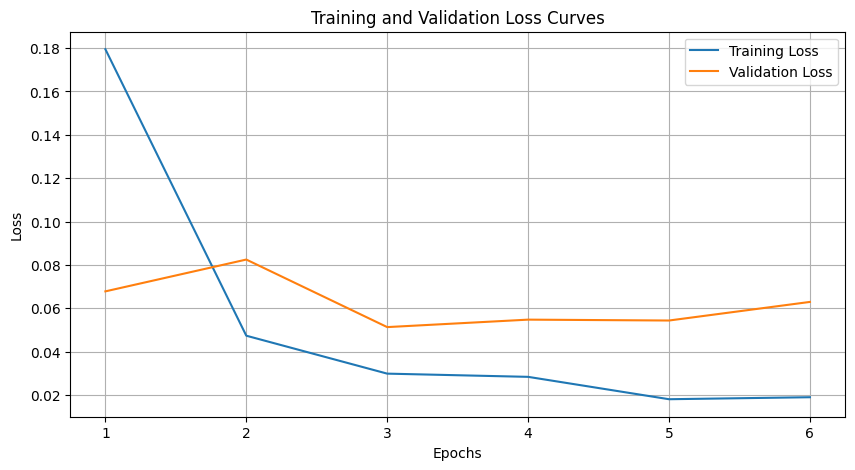

In [10]:
# Train model
train_model(model, train_loader, val_loader, criterion, optimizer, epochs=20)


In [13]:
plt.savefig("my_lc.png") 

<Figure size 640x480 with 0 Axes>

In [11]:
# Save the trained model with error handling
model_path = "/kaggle/working/model_VitCls.pth"
try:
    torch.save(model.state_dict(), model_path)
    print(f"Model saved successfully to {model_path}")
except Exception as e:
    print(f"Error saving model: {e}")
    raise


Model saved successfully to /kaggle/working/model_VitCls.pth


Testing: 100%|██████████| 225/225 [00:56<00:00,  3.96it/s]


Test Accuracy: 93.68%
Test Precision: 0.9504
Test Recall: 0.9368
Test F1 Score: 0.9348


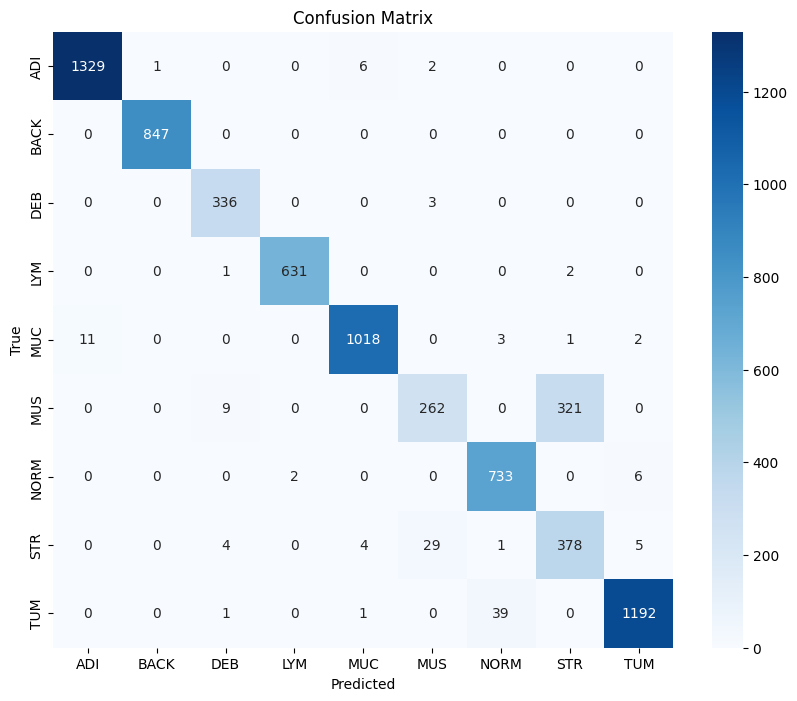

<Figure size 640x480 with 0 Axes>

In [14]:
def evaluate_model_with_metrics(model, test_loader, class_names):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc="Testing"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    f1 = f1_score(all_labels, all_preds, average='weighted')

    print(f"Test Accuracy: {accuracy * 100:.2f}%")
    print(f"Test Precision: {precision:.4f}")
    print(f"Test Recall: {recall:.4f}")
    print(f"Test F1 Score: {f1:.4f}")

    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()
    plt.savefig('/kaggle/working/CM.png', format='png', dpi=600)

# Evaluate on test set with metrics
evaluate_model_with_metrics(model, test_loader, dataset.classes)

In [15]:
    from IPython.display import FileLink
    FileLink(r'model_VitCls.pth')

/kaggle/working/model_VitCls.pth

In [16]:
# Install grad-cam
!pip install grad-cam --quiet


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 69.5 MB/s eta 0:00:00:00:010:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 99.6 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 79.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 2.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 29.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.2

In [17]:
# Explicitly import pytorch_grad_cam components
try:
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image
except ImportError as e:
    print(f"Error importing pytorch_grad_cam: {e}")
    print("Ensure 'grad-cam' is installed correctly with: !pip install grad-cam")
    raise


In [21]:
from PIL import Image
import numpy as np
import gc
# Fixed Grad-CAM implementation for ViT
class ViTModelWrapper(torch.nn.Module):
    def __init__(self, model):
        super(ViTModelWrapper, self).__init__()
        self.model = model

    def forward(self, x):
        return self.model(x)

def reshape_transform_vit(x):
    activations = x[:, 1:, :]  # Remove CLS token: (B, 197, hidden) -> (B, 196, hidden)
    activations = activations.view(activations.shape[0], 14, 14, activations.shape[2])  # Reshape to (B, 14, 14, hidden)
    activations = activations.permute(0, 3, 1, 2)  # To (B, hidden, 14, 14)
    return activations

# Data transform for Grad-CAM
data_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

def denormalize(tensor):
    mean = np.array([0.5, 0.5, 0.5])
    std = np.array([0.5, 0.5, 0.5])
    tensor = tensor.cpu().numpy().transpose((1, 2, 0))
    tensor = std * tensor + mean
    tensor = np.clip(tensor, 0, 1)
    return tensor

# Load ViT model
model = ViTClassifier(num_classes=num_classes).to(device)
try:
    ViT_state = torch.load('/kaggle/working/model_VitCls.pth', map_location=device)
    model_state = model.state_dict()
    for k, v in ViT_state.items():
        if k in model_state and model_state[k].shape == v.shape:
            model_state[k] = v
    model.load_state_dict(model_state, strict=False)
except FileNotFoundError:
    print("Model weights not found. Please ensure the model is trained and saved.")
    raise
model = model.to(device)

# Target layer for Grad-CAM
target_layer = model.vit.vit.encoder.layer[-2].output

def visualize_gradcam(image_path, model, target_layer, target_class):
    wrapper = ViTModelWrapper(model)
    cam = GradCAM(model=wrapper, target_layers=[target_layer], reshape_transform=reshape_transform_vit)
    
    image = Image.open(image_path).convert('RGB')
    input_tensor = data_transform(image).unsqueeze(0).to(device)
    targets = [ClassifierOutputTarget(target_class)]
    
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    input_image = denormalize(input_tensor[0])
    visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)
    
    class_name = [k for k, v in dataset.class_to_idx.items() if v == target_class][0]
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(input_image)
    plt.title(f"Original Image (Class: {class_name})")
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(visualization)
    plt.title("Grad-CAM")
    plt.axis('off')
    output_path = f'/kaggle/working/gradcam_{os.path.basename(image_path)}.png'
    plt.savefig(output_path, format='png', dpi=300, bbox_inches='tight')
    plt.close()  # Close plot to free memory
    print(f"Grad-CAM plot saved to {output_path}")
    
    # Clean up
    del input_tensor, grayscale_cam, visualization
    torch.cuda.empty_cache()
    gc.collect()

def generate_gradcam_per_label(model, dataloader, target_layer, class_to_idx):
    wrapper = ViTModelWrapper(model)
    cam = GradCAM(model=wrapper, target_layers=[target_layer], reshape_transform=reshape_transform_vit)
    
    correct_samples = {label: None for label in class_to_idx.values()}
    model.eval()
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            for i in range(inputs.size(0)):
                label = labels[i].item()
                if preds[i].item() == label and correct_samples[label] is None:
                    correct_samples[label] = (inputs[i].unsqueeze(0), label)
            if all(v is not None for v in correct_samples.values()):
                break
    
    for label, sample in correct_samples.items():
        if sample is None:
            class_name = [k for k, v in class_to_idx.items() if v == label][0]
            print(f"No correct predictions found for class {class_name}. Skipping Grad-CAM.")
            continue
        input_tensor, label_idx = sample
        targets = [ClassifierOutputTarget(label_idx)]
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        
        input_image = denormalize(input_tensor[0])
        visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)
        
        class_name = [k for k, v in class_to_idx.items() if v == label_idx][0]
        plt.figure(figsize=(8, 4))
        plt.subplot(1, 2, 1)
        plt.imshow(input_image)
        plt.title(f"Original Image (Class: {class_name})")
        plt.axis('off')
        plt.subplot(1, 2, 2)
        plt.imshow(visualization)
        plt.title(f"Grad-CAM for {class_name}")
        plt.axis('off')
        output_path = f'/kaggle/working/gradcam_label_{class_name}.png'
        plt.savefig(output_path, format='png', dpi=300, bbox_inches='tight')
        plt.close()
        print(f"Grad-CAM for label {class_name} saved to {output_path}")
        
        # Clean up
        del input_tensor, grayscale_cam, visualization
        torch.cuda.empty_cache()
        gc.collect()

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [22]:
# Generate Grad-CAM visualizations
sample_image_path = test_dataset.samples[0][0]
sample_class = labels[0]
visualize_gradcam(sample_image_path, model, target_layer, sample_class)
generate_gradcam_per_label(model, test_loader, target_layer, dataset.class_to_idx)


Grad-CAM plot saved to /kaggle/working/gradcam_ADI-TCGA-AAICEQFN.tif.png
Grad-CAM for label ADI saved to /kaggle/working/gradcam_label_ADI.png
Grad-CAM for label BACK saved to /kaggle/working/gradcam_label_BACK.png
Grad-CAM for label DEB saved to /kaggle/working/gradcam_label_DEB.png
Grad-CAM for label LYM saved to /kaggle/working/gradcam_label_LYM.png
Grad-CAM for label MUC saved to /kaggle/working/gradcam_label_MUC.png
Grad-CAM for label MUS saved to /kaggle/working/gradcam_label_MUS.png
Grad-CAM for label NORM saved to /kaggle/working/gradcam_label_NORM.png
Grad-CAM for label STR saved to /kaggle/working/gradcam_label_STR.png
Grad-CAM for label TUM saved to /kaggle/working/gradcam_label_TUM.png
